# 25 — Does the border neuropil loss recover? And what is the neuronal RNA in grey-matter myeloid cells?

**A. Recovery.** Notebook 20, section 9: ATP1A1 neuropil is ~15–20 % lower in lesions within ~75 µm of grey matter
(at matched distance), and not deeper. Is that loss there at the peak and gone in recovery (remission, monophasic),
or does it persist into chronic disease? Per animal: lesion ÷ healthy white matter within 0–75 µm of grey matter, in
25 µm distance bands (≥ 20 cells per band and group; log ratios averaged over bands), curated lesions, all five
runs; the same at 100–400 µm as the no-loss control. Stage groups: active (onset, peaks), recovery (remissions,
monophasic), chronic late (MILD/SEVERE 16/30). This also checks the "damage memory" neuropil trend of notebooks
11/12, which was never matched for distance to grey matter.

**B. The grey-matter lead.** Notebook 23: in grey-matter lesion cores myeloid cells hold more neuron-derived RNA
relative to their surroundings than astrocytes (×1.39, 40/41 animals). Engulfed neuronal material or spillover
from neurons the cells touch? Two tests:
1. **Depth:** share of the neuron-derived RNA inside a myeloid cell that sits deep (≥ 2 µm from the outline) vs at
   the rim, ÷ the same share for the cell's own phagocyte RNA (≈ 1 = spread like own RNA, as engulfed material
   would be; well below 1 = rim, like spillover); astrocytes (own RNA: astrocyte genes) as the comparison.
2. **Contact:** myeloid cells whose nearest neuron is ≤ 12 µm away (touching) vs ≥ 25 µm away. Spillover predicts
   neuronal RNA only in the touching ones; engulfed material should remain in the distant ones too.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.stats import mannwhitneyu, spearmanr, wilcoxon

from beyondboundaries import plotting

plotting.style()
SRC = "notebooks/25_border_recovery_and_gm_myeloid.ipynb"
OUT = ROOT / "results" / "25_border_recovery_and_gm_myeloid"
OUT.mkdir(parents=True, exist_ok=True)
COL = plotting.CATEGORICAL
WM, GM = ["WM", "WM_Meningeal"], ["GM", "DorsalHorn", "VentralHorn"]
GROUPS = {"active": ["ONSET1", "ONSET2", "OS1", "PEAK1", "PEAK2", "PEAK2_MILD", "PEAK3"],
          "recovery": ["REMISSION1", "REMISSION2", "REMISSION2_LONG", "MONOPHASIC"],
          "chronic late": ["MILD16", "MILD30", "SEVERE16", "SEVERE30"]}
STAGE_ORDER = [s for v in GROUPS.values() for s in v]

## A. Border neuropil loss across the disease course

In [2]:
a = ad.read_h5ad(ROOT / "data" / "RRMAP2_all_runs.h5ad", backed="r")
obs = a.obs[["sample_name", "meta_sample_id", "run_id", "stage", "model", "Global_anatomical_region",
             "Curated_niche_state", "x_centroid", "y_centroid"]].copy()
a.file.close()
for c in ["sample_name", "meta_sample_id", "run_id", "stage", "model", "Global_anatomical_region", "Curated_niche_state"]:
    obs[c] = obs[c].astype(str)
fa = pd.read_parquet(ROOT / "data" / "features_norm_all.parquet",
                     columns=["segmentation_method", "bnd_terr_mean", "bnd_scale", "bnd_bg_local"])
fa = fa[fa.segmentation_method == "Segmented by interior stain (18S)"]
w = obs.join((fa.bnd_terr_mean * fa.bnd_scale + fa.bnd_bg_local).rename("atp_raw"), how="inner")
w = w[w.Global_anatomical_region.isin(WM)].copy()
# cells < 20 µm from another tissue piece excluded (pieces touch in runs 1-3)
other = pd.Series(np.inf, index=obs.index)
for sid, g in obs.assign(sec=obs.index.str.split(":").str[0]).groupby("sec"):
    xy, pcs = g[["x_centroid", "y_centroid"]].to_numpy(), g.meta_sample_id.to_numpy()
    for p_ in np.unique(pcs):
        m_ = pcs == p_
        if not m_.all():
            other[g.index[m_]] = cKDTree(xy[~m_]).query(xy[m_])[0]
w = w[other.reindex(w.index) >= 20]
w["d_gm"] = np.nan
for pc, g in obs.groupby("meta_sample_id"):
    gm = g[g.Global_anatomical_region.isin(GM)]
    idx = w.index[w.meta_sample_id == pc]
    if len(gm) >= 20 and len(idx):
        w.loc[idx, "d_gm"] = cKDTree(gm[["x_centroid", "y_centroid"]].to_numpy()).query(
            w.loc[idx, ["x_centroid", "y_centroid"]].to_numpy())[0]
w["atp_index"] = w.atp_raw / w.groupby("meta_sample_id").atp_raw.transform("median")
w["z"] = np.select([w.Curated_niche_state.str.startswith("Lesion"), w.Curated_niche_state == "Physiological"],
                   ["lesion", "healthy"], "other")
w = w[(w.z != "other") & w.d_gm.notna()]
grp_of = {s: k for k, v in GROUPS.items() for s in v}
w["group"] = w.stage.map(grp_of)
print(w.groupby("group").sample_name.nunique().to_dict(), f"{len(w):,} WM cells")


def animal_effect(s, bands):
    """mean over distance bands of log(median lesion index / median healthy index), bands with >= 20 cells each."""
    vals = []
    for lo, hi in bands:
        b = s[(s.d_gm >= lo) & (s.d_gm < hi)]
        L, H = b[b.z == "lesion"].atp_index, b[b.z == "healthy"].atp_index
        if len(L) >= 20 and len(H) >= 20:
            vals.append(np.log(L.median() / H.median()))
    return (np.mean(vals), len(vals)) if vals else (np.nan, 0)


BORDER = [(0, 25), (25, 50), (50, 75)]
DEEP = [(100, 150), (150, 200), (200, 300), (300, 400)]
rows = []
for an, s in w.groupby("sample_name"):
    eb, nb = animal_effect(s, BORDER)
    ed, nd = animal_effect(s, DEEP)
    rows.append(dict(animal=an, stage=s.stage.iloc[0], group=s.group.iloc[0], run=s.run_id.iloc[0],
                     arm="chronic" if s.model.iloc[0].startswith("CHRONIC") else "RR",
                     border_ratio=np.exp(eb), border_bands=nb, deep_ratio=np.exp(ed), deep_bands=nd))
A = pd.DataFrame(rows).set_index("animal")
A.round(3).to_csv(OUT / "border_neuropil_per_animal.csv")
summ = A.groupby("group").agg(animals=("border_ratio", lambda x: x.notna().sum()),
                              border_median=("border_ratio", "median"),
                              border_share_below_1=("border_ratio", lambda x: (x.dropna() < 1).mean()),
                              deep_median=("deep_ratio", "median"))
summ.round(3)

{'active': 28, 'chronic late': 13, 'recovery': 13} 543,547 WM cells


,animals,border_median,border_share_below_1,deep_median
group,,,,
active,22,0.822,0.773,0.998
chronic late,13,0.926,0.615,1.050
recovery,13,0.834,1.000,0.998


In [3]:
rows = []
for col in ["border_ratio", "deep_ratio"]:
    for gname in GROUPS:
        x = np.log(A.loc[A.group == gname, col].dropna())
        if len(x) >= 5:
            rows.append(dict(readout=col, group=gname, animals=len(x), ratio=np.exp(x.median()),
                             p_vs_1=wilcoxon(x).pvalue))
    for g1, g2 in [("active", "recovery"), ("active", "chronic late"), ("recovery", "chronic late")]:
        x1, x2 = A.loc[A.group == g1, col].dropna(), A.loc[A.group == g2, col].dropna()
        if len(x1) >= 4 and len(x2) >= 4:
            rows.append(dict(readout=col, group=f"{g1} vs {g2}", animals=len(x1) + len(x2),
                             ratio=np.exp(np.log(x1).median() - np.log(x2).median()),
                             p_vs_1=mannwhitneyu(np.log(x1), np.log(x2)).pvalue))
tests = pd.DataFrame(rows)
tests.round(4).to_csv(OUT / "border_neuropil_tests.csv", index=False)
tests.round(3)

,readout,group,animals,ratio,p_vs_1
0,border_ratio,active,22,0.822,0.001
1,border_ratio,recovery,13,0.834,0.000
2,border_ratio,chronic late,13,0.926,0.057
3,border_ratio,active vs recovery,35,0.986,0.597
4,border_ratio,active vs chronic late,35,0.888,0.878
5,border_ratio,recovery vs chronic late,26,0.901,0.573
6,deep_ratio,active,13,0.998,0.839
7,deep_ratio,recovery,12,0.998,0.791
8,deep_ratio,chronic late,11,1.050,0.638
9,deep_ratio,active vs recovery,25,1.000,0.978


PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/results/25_border_recovery_and_gm_myeloid/border_neuropil_by_stage.png')

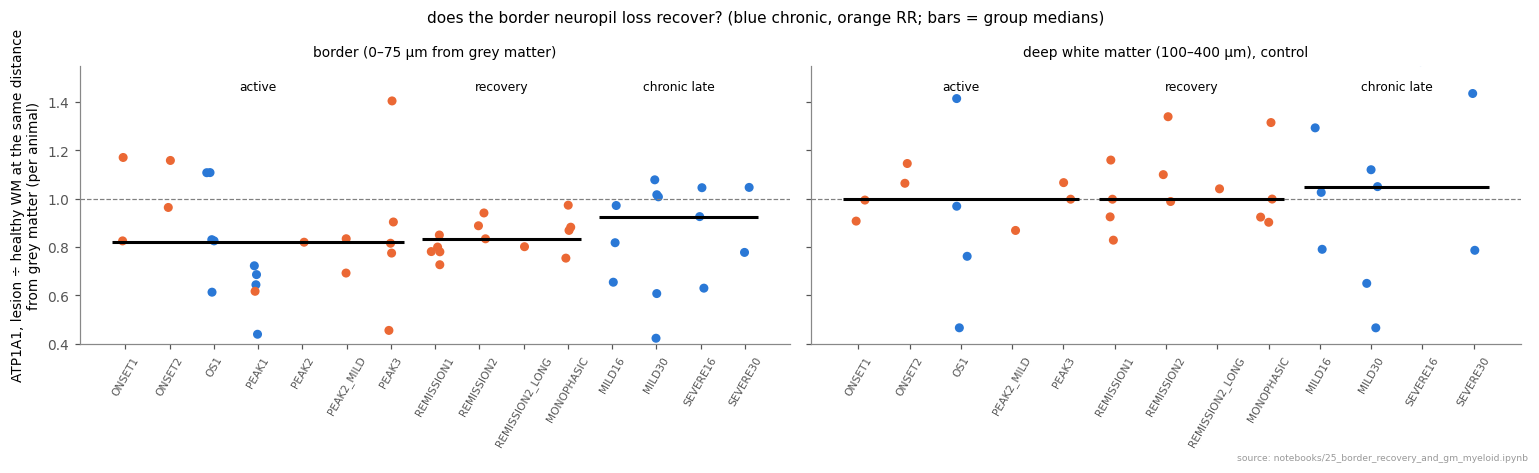

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
rng = np.random.default_rng(0)
for ax, col, title in [(axs[0], "border_ratio", "border (0–75 µm from grey matter)"),
                       (axs[1], "deep_ratio", "deep white matter (100–400 µm), control")]:
    d_ = A.dropna(subset=[col])
    order = [s for s in STAGE_ORDER if s in set(d_.stage)]
    x = d_.stage.map({s: i for i, s in enumerate(order)})
    ax.scatter(x + rng.normal(0, 0.07, len(d_)), d_[col], c=[COL[0] if a_ == "chronic" else COL[1] for a_ in d_.arm],
               s=24)
    ax.set_xticks(range(len(order)), order, rotation=60, fontsize=7)
    ax.axhline(1, color="0.5", ls="--", lw=0.8)
    for k, (gname, members) in enumerate(GROUPS.items()):
        xs = [order.index(s) for s in members if s in order]
        if xs:
            m = d_[d_.group == gname][col].median()
            ax.hlines(m, min(xs) - 0.3, max(xs) + 0.3, color="black", lw=2)
            ax.text(np.mean(xs), 1.45, gname, ha="center", fontsize=8)
    ax.set_title(title, fontsize=9)
axs[0].set_ylabel("ATP1A1, lesion ÷ healthy WM at the same distance\nfrom grey matter (per animal)")
axs[0].set_ylim(0.4, 1.55)
fig.suptitle("does the border neuropil loss recover? (blue chronic, orange RR; bars = group medians)", fontsize=10)
fig.tight_layout()
plotting.save_fig(fig, "border_neuropil_by_stage", OUT, SRC)

## B. Neuron-derived RNA in grey-matter myeloid cells: engulfed or spillover?
Per-cell compartment counts from notebook 23 (`data/subcellular/cells_compartments.parquet`, all runs).

In [5]:
c = pd.read_parquet(ROOT / "data" / "subcellular" / "cells_compartments.parquet")
c = c[c.Global_anatomical_region.isin(GM)].copy()
for lay in ["rim", "deep", "halo"]:
    c[f"{lay}_neuro"] = c.get(f"{lay}_axon", 0) + c.get(f"{lay}_neuron_soma", 0)
c["neuro_cell"] = c.axon_cell + c.neuron_soma_cell
MYEL, ASTRO = ["MDM", "Microglia", "CAM"], ["Reactive astro", "Homeostatic astro"]
NEUR = ["Exc neuron", "Inh neuron", "Chol neuron"]
c["d_neuron"] = np.nan
for pc, g in c.groupby("meta_sample_id"):
    n = g[g.ctype.astype(str).isin(NEUR)]
    if len(n) >= 10:
        dist, _ = cKDTree(n[["x_centroid", "y_centroid"]].to_numpy()).query(g[["x_centroid", "y_centroid"]].to_numpy(), k=2)
        c.loc[g.index, "d_neuron"] = np.where(g.ctype.astype(str).isin(NEUR), dist[:, 1], dist[:, 0])
my = c[c.ctype.astype(str).isin(MYEL)]
ast = c[c.ctype.astype(str).isin(ASTRO)]


def depth_index(s, own):
    dn = s.deep_neuro.sum() / max(s.deep_neuro.sum() + s.rim_neuro.sum(), 1)
    do = s[f"deep_{own}"].sum() / max(s[f"deep_{own}"].sum() + s[f"rim_{own}"].sum(), 1)
    return dn / do if do > 0 else np.nan


def uptake(s):
    h = s.halo_neuro.sum() / s.halo_area.sum()
    return (s.neuro_cell.sum() / s.cell_area.sum()) / h if h > 0 else np.nan


rows = []
for an in sorted(set(my.sample_name)):
    for zn in ["core", "healthy"]:
        m_, a_ = my[(my.sample_name == an) & (my.zone == zn)], ast[(ast.sample_name == an) & (ast.zone == zn)]
        if len(m_) < 20 or len(a_) < 20:
            continue
        near, far = m_[m_.d_neuron <= 12], m_[m_.d_neuron >= 25]
        anear, afar = a_[a_.d_neuron <= 12], a_[a_.d_neuron >= 25]
        rows.append(dict(animal=an, zone=zn, myeloid=len(m_), astrocytes=len(a_),
                         depth_myeloid=depth_index(m_, "phago"), depth_astro=depth_index(a_, "astro"),
                         uptake_myeloid=uptake(m_), uptake_astro=uptake(a_),
                         uptake_myeloid_touching=uptake(near) if len(near) >= 10 else np.nan,
                         uptake_myeloid_distant=uptake(far) if len(far) >= 10 else np.nan,
                         uptake_astro_touching=uptake(anear) if len(anear) >= 10 else np.nan,
                         uptake_astro_distant=uptake(afar) if len(afar) >= 10 else np.nan))
B = pd.DataFrame(rows)
B.round(3).to_csv(OUT / "gm_myeloid_neuro_rna_per_animal.csv", index=False)


def paired(x, y):
    m = x.notna() & y.notna() & (x > 0) & (y > 0)
    lf = np.log2(x[m] / y[m])
    return dict(animals=int(m.sum()), ratio=2 ** lf.median() if len(lf) else np.nan, share_above=(lf > 0).mean(),
                p=wilcoxon(lf).pvalue if len(lf) >= 5 else np.nan)


rows = []
for zn in ["core", "healthy"]:
    b = B[B.zone == zn]
    rows += [dict(zone=zn, test="uptake: myeloid ÷ astrocyte", **paired(b.uptake_myeloid, b.uptake_astro)),
             dict(zone=zn, test="depth index: myeloid ÷ astrocyte", **paired(b.depth_myeloid, b.depth_astro)),
             dict(zone=zn, test="myeloid uptake: touching ÷ distant from a neuron",
                  **paired(b.uptake_myeloid_touching, b.uptake_myeloid_distant)),
             dict(zone=zn, test="astrocyte uptake: touching ÷ distant", **paired(b.uptake_astro_touching,
                                                                               b.uptake_astro_distant)),
             dict(zone=zn, test="distant cells only: myeloid ÷ astrocyte",
                  **paired(b.uptake_myeloid_distant, b.uptake_astro_distant))]
    for col in ["depth_myeloid", "depth_astro"]:
        rows.append(dict(zone=zn, test=f"{col} (median level)", animals=b[col].notna().sum(), ratio=b[col].median()))
bt = pd.DataFrame(rows)
bt.round(4).to_csv(OUT / "gm_myeloid_tests.csv", index=False)
bt.round(3)

,zone,test,animals,ratio,share_above,p
0,core,uptake: myeloid ÷ astrocyte,41,1.348,0.976,0.000
1,core,depth index: myeloid ÷ astrocyte,41,1.044,0.634,0.144
2,core,myeloid uptake: touching ÷ distant from a neuron,35,1.251,0.829,0.000
3,core,astrocyte uptake: touching ÷ distant,32,1.341,0.969,0.000
4,core,distant cells only: myeloid ÷ astrocyte,41,1.348,0.902,0.000
5,core,depth_myeloid (median level),41,0.887,NaN,NaN
6,core,depth_astro (median level),41,0.847,NaN,NaN
7,healthy,uptake: myeloid ÷ astrocyte,54,1.138,0.852,0.000
8,healthy,depth index: myeloid ÷ astrocyte,54,0.894,0.204,0.000
9,healthy,myeloid uptake: touching ÷ distant from a neuron,50,1.175,0.840,0.000


PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/results/25_border_recovery_and_gm_myeloid/gm_myeloid_per_animal.png')

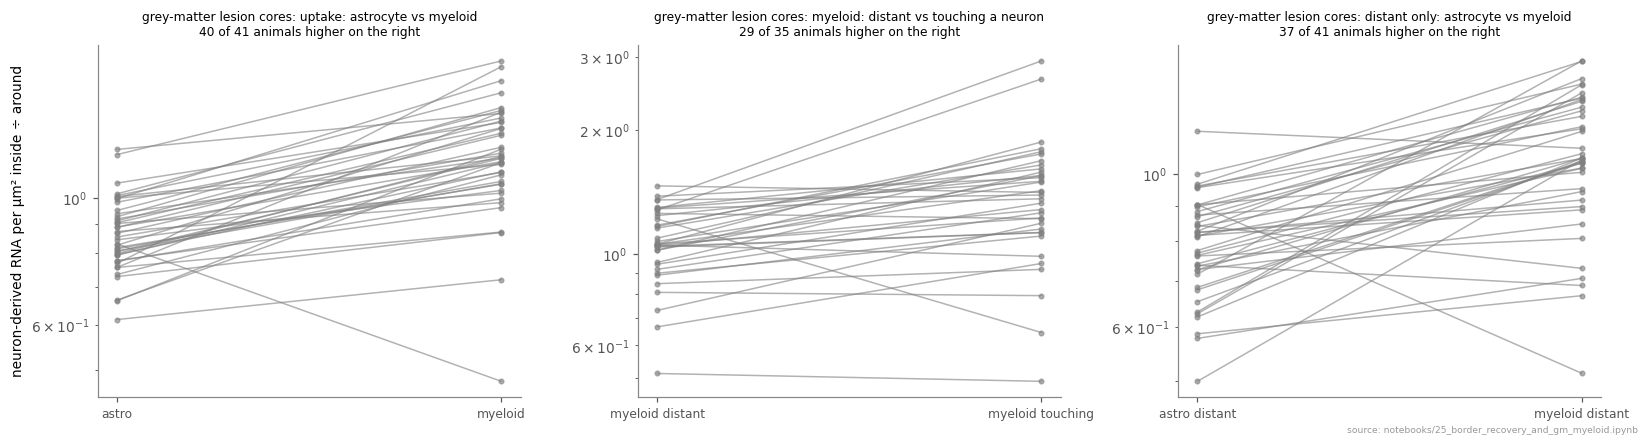

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (x, y, lab) in zip(axs, [("uptake_astro", "uptake_myeloid", "uptake: astrocyte vs myeloid"),
                                 ("uptake_myeloid_distant", "uptake_myeloid_touching",
                                  "myeloid: distant vs touching a neuron"),
                                 ("uptake_astro_distant", "uptake_myeloid_distant", "distant only: astrocyte vs myeloid")]):
    b = B[B.zone == "core"][[x, y]].dropna()
    for _, r in b.iterrows():
        ax.plot([0, 1], [r[x], r[y]], color="0.5", alpha=0.6, marker="o", ms=3, lw=1)
    ax.set_xticks([0, 1], [x.replace("uptake_", "").replace("_", " "), y.replace("uptake_", "").replace("_", " ")],
                  fontsize=8)
    ax.set_yscale("log")
    ax.set_title(f"grey-matter lesion cores: {lab}\n{(b[y] > b[x]).sum()} of {len(b)} animals higher on the right",
                 fontsize=8)
axs[0].set_ylabel("neuron-derived RNA per µm² inside ÷ around")
fig.tight_layout()
plotting.save_fig(fig, "gm_myeloid_per_animal", OUT, SRC)

## Findings

> **A. The border neuropil loss does not recover.** Per animal, lesion ÷ healthy white matter within 0–75 µm of grey
> matter (matched distance bands): active ×0.82 (22 animals, p = 0.002), **recovery ×0.83 (13 animals, all 13
> below 1, p < 0.001)**, chronic late ×0.93 (13 animals, p = 0.06, scattered); no group differs from another
> (p ≥ 0.57). Deep white matter (100–400 µm) is ×1.00–1.05 in every group. So the ATP1A1 loss at the grey/white
> border appears with active disease and persists through remission and monophasic recovery. This **replaces** the
> earlier "neuropil returns towards normal in recovery" (notebooks 11/12), which pooled white and grey matter and was
> not matched for distance to grey matter.
>
> **B. Neuronal RNA in grey-matter myeloid cells: more than contact spillover, but not deep inside the cell
> (unresolved).** In grey-matter lesion cores myeloid cells hold more neuron-derived RNA relative to their
> surroundings than astrocytes (×1.35, 40/41 animals), against ×1.14 in healthy grey matter. Both cell types hold
> more when touching a neuron's soma (myeloid ×1.25, astrocytes ×1.34): there is a spillover component. But among
> cells **not** touching a neuron (≥ 25 µm) the myeloid excess remains (×1.35, 37/41), so contact with neuronal cell
> bodies does not explain it. The RNA is not deeper inside myeloid cells than their own RNA, relative to
> astrocytes (depth index ×1.04, p = 0.14), which argues against large engulfed deposits. Most consistent with
> myeloid cells wrapping neuronal processes (neurites are not in the contact test) or with small amounts of
> recently taken-up material; the images or a neurite marker would be needed to decide.